# Pedestal Shape Comparisons at Matched Power

Compare saved spline and modified-tanh $T_e$ and $n_e$ profiles using successful intervals near a configurable power target. The current target is spline-derived $P_{\mathrm{SOL}}=1.30$ MW within $\pm 10\%$. Candidate intervals must last at least 0.08 s and contain at least 100 fit data points; plasma-regime labels are retained rather than filtered to EDA. Tables report interval, regime, fit coverage, gas puff, $I_p$, $P_{\mathrm{tot}}$, $P_{\mathrm{ECRH}}$, and $P_{\mathrm{SOL}}$.

The first comparison uses the fixed four-shot set 38743, 38744, 38742, and 38067 (all 0.7 MA), maximizing measured gas-puff span while matching power and holding $I_p$ within 1%. No substitute shot is used. The final comparison varies current while matching power and holding gas puff within 6%. Power is an interval-averaged saved-fit estimate; the notebook reads existing fits and does not refit profiles.

In [ ]:
from pathlib import Path
import itertools
import json
import sys

import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.interpolate import BSpline
from ipfnpytools.plot import plots as ipfn_plots
from ipfnpytools.save_figure import save_figure as save_fig

cwd = Path.cwd()
CONFIG_RELATIVE_PATH = Path("configs/pipeline_config_run05_new_outlier.yaml")
PROJECT_ROOT = next(
    (parent for parent in (cwd, *cwd.parents) if (parent / CONFIG_RELATIVE_PATH).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Could not find {CONFIG_RELATIVE_PATH} from {cwd}")

CONFIG_PATH = PROJECT_ROOT / CONFIG_RELATIVE_PATH
with CONFIG_PATH.open() as config_file:
    CONFIG = yaml.safe_load(config_file)

OUTPUT_DIR = Path(CONFIG["output_dir"])
DATABASE_CSV = Path(CONFIG["output_database_csv"])
FIT_CONFIG = CONFIG["fit_config"]["fits"]
SPLINE_CONFIG = FIT_CONFIG["spline"]
KNOT_COUNT_SHIFT = int(SPLINE_CONFIG["knot_count_shift"])
SPLINE_LABEL = f"Spline (knot shift {KNOT_COUNT_SHIFT:+d})"

GAS_SCAN_SHOTS = [38743, 38744, 38049, 38067]
GAS_SCAN_CASES = {
    38743: "high gas, 0.7 MA",
    38744: "medium-high gas, 0.7 MA",
    38049: "medium gas, 0.7 MA",
    38067: "medium-low gas, 0.7 MA",
}
if set(GAS_SCAN_SHOTS) != set(GAS_SCAN_CASES):
    raise ValueError("GAS_SCAN_CASES must label every gas-scan shot exactly once")
CURRENT_SCAN_SHOTS = [38808, 36124, 36980, 38049]
CURRENT_SCAN_CASES = {
    38808: "medium gas, 0.6 MA",
    36124: "medium gas, 0.8 MA",
    36980: "medium gas, 0.5 MA",
    38049: "medium gas, 0.7 MA",
}

MATCH_POWER_KIND = "P_SOL"
MATCH_POWER_TARGET_MW = 1.3
MATCH_POWER_RELATIVE_TOLERANCE = 0.10
MIN_INTERVAL_DURATION_S = 0.08
MIN_FIT_POINTS = 100
MAX_RELATIVE_SPAN = {"Ip": 0.01, "Gas puff": 0.06}
POWER_FIELDS = {
    "P_SOL": "spline_P_SOL",
    "P_TOT": "TTH|P_NET",
    "P_ECRH": "ECS|PECRH",
}
P_NET_FIELD = "TTH|P_NET"
ECRH_FIELD = "ECS|PECRH"
IP_FIELD = "FPC|IpiFP"
GAS_FIELD = "___|gaspuff_tot"
GAS_PUFF_SCALE = 1e-21
SOL_FIELD = "spline_P_SOL"
SOL_DATABASE_FIELD = "|P_TOT-Pr_sep"
PEDESTAL_XLIM = (-0.04, 0.04)
THESIS_FIGURES_DIR = Path(
    "/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/"
    "chapters/Results/Fueling/figures"
)

if MATCH_POWER_KIND not in POWER_FIELDS:
    raise ValueError(f"MATCH_POWER_KIND must be one of {sorted(POWER_FIELDS)}")
if MATCH_POWER_TARGET_MW <= 0 or MATCH_POWER_RELATIVE_TOLERANCE <= 0:
    raise ValueError("The matched-power target and relative tolerance must be positive")
if MIN_INTERVAL_DURATION_S <= 0 or MIN_FIT_POINTS <= 0:
    raise ValueError("Minimum interval duration and fit-point count must be positive")

MATCH_POWER_FIELD = POWER_FIELDS[MATCH_POWER_KIND]
MATCH_POWER_SCALE = 1e-6

assert CONFIG["equilibrium"] == "EQH"
assert SPLINE_CONFIG["method"] == "ipfn_spline"
assert SPLINE_CONFIG["knot_strategy"] == "edge_biased_quantile"


def _fit_point_count(result_path):
    if not isinstance(result_path, str) or not result_path:
        return 0
    result_path = Path(result_path)
    if not result_path.is_file():
        return 0
    with result_path.open() as result_file:
        return int(json.load(result_file).get("n_points", 0))


def load_power_matched_candidates(shot_ids):
    shot_ids = list(shot_ids)
    database = pd.read_csv(DATABASE_CSV, low_memory=False)
    database = database.loc[database["shot"].isin(shot_ids)].copy()
    status_frames = []
    for shot_id in shot_ids:
        status_path = OUTPUT_DIR / f"shot_{shot_id}" / "interval_status.csv"
        if not status_path.is_file():
            raise FileNotFoundError(f"Interval status file not found: {status_path}")
        status_frames.append(pd.read_csv(status_path))

    statuses = pd.concat(status_frames, ignore_index=True)
    database["_t_begin_key"] = database["t_begin (s)"].round(3)
    database["_t_end_key"] = database["t_end (s)"].round(3)
    statuses["_t_begin_key"] = statuses["t_begin"].round(3)
    statuses["_t_end_key"] = statuses["t_end"].round(3)
    intervals = database.merge(
        statuses[["shot_id", "_t_begin_key", "_t_end_key", "status", "result"]],
        left_on=["shot", "_t_begin_key", "_t_end_key"],
        right_on=["shot_id", "_t_begin_key", "_t_end_key"],
        how="left",
        validate="one_to_one",
    )
    intervals["duration_s"] = intervals["t_end (s)"] - intervals["t_begin (s)"]
    intervals["fit points"] = intervals["result"].map(_fit_point_count)
    intervals["matched power (MW)"] = (
        pd.to_numeric(intervals[MATCH_POWER_FIELD], errors="coerce") * MATCH_POWER_SCALE
    )
    target_tolerance_mw = MATCH_POWER_TARGET_MW * MATCH_POWER_RELATIVE_TOLERANCE
    eligible_mask = (
        intervals["status"].isin(["ok", "warning"])
        & (intervals["duration_s"] >= MIN_INTERVAL_DURATION_S)
        & (intervals["fit points"] >= MIN_FIT_POINTS)
        & np.isfinite(intervals["matched power (MW)"])
        & (
            (intervals["matched power (MW)"] - MATCH_POWER_TARGET_MW).abs()
            <= target_tolerance_mw
        )
    )
    return intervals, intervals.loc[eligible_mask].copy()

print(f"Pinned config: {CONFIG_PATH}")
print(f"Saved fitted database: {DATABASE_CSV}")
print(
    f"Matched {MATCH_POWER_KIND}: {MATCH_POWER_TARGET_MW:.2f} MW "
    f"(+/- {MATCH_POWER_RELATIVE_TOLERANCE:.0%}); "
    f"minimum interval {MIN_INTERVAL_DURATION_S:.2f} s and {MIN_FIT_POINTS} fit points."
)
print("Accepted fit status is required; plasma-regime labels are retained without filtering.")
print(
    "Saved-fit selection: "
    f"{SPLINE_CONFIG['method']} / {SPLINE_CONFIG['knot_strategy']} / "
    f"knot shift {KNOT_COUNT_SHIFT:+d}"
)
print("No fitting or environment creation is performed by this notebook.")

Pinned config: /shares/users/work/joanune/Desktop/TS_profile_fitter/configs/pipeline_config_run05_new_outlier.yaml
Saved fitted database: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_05_new_outlier_rule/34383---38808_database_dt-0.1s_fitted.csv
Matched P_SOL: 1.30 MW (+/- 10%); minimum interval 0.08 s and 100 fit points.
Accepted fit status is required; plasma-regime labels are retained without filtering.
Saved-fit selection: ipfn_spline / edge_biased_quantile / knot shift +2
No fitting or environment creation is performed by this notebook.


In [2]:
if not DATABASE_CSV.is_file():
    raise FileNotFoundError(f"Fitted database CSV not found: {DATABASE_CSV}")

all_intervals, candidates = load_power_matched_candidates(GAS_SCAN_SHOTS)
candidate_summary = pd.DataFrame(
    [
        {
            "shot": shot_id,
            "gas-puff case": GAS_SCAN_CASES[shot_id],
            "qualified intervals at target power": int((candidates["shot"] == shot_id).sum()),
            "regimes represented": int(candidates.loc[candidates["shot"] == shot_id, "label"].nunique()),
        }
        for shot_id in GAS_SCAN_SHOTS
    ]
)
print(
    f"Qualified intervals require an accepted fit, >= {MIN_INTERVAL_DURATION_S:.2f} s, "
    f">= {MIN_FIT_POINTS} fit points, and {MATCH_POWER_KIND} within "
    f"+/- {MATCH_POWER_RELATIVE_TOLERANCE:.0%} of {MATCH_POWER_TARGET_MW:.2f} MW."
)
display(candidate_summary)

selected_shots = list(GAS_SCAN_SHOTS)
selected_candidates = {
    shot_id: candidates.loc[candidates["shot"] == shot_id]
    .sort_values(["t_begin (s)", "t_end (s)"])
    .to_dict("records")
    for shot_id in selected_shots
}
empty_cases = [shot_id for shot_id, rows in selected_candidates.items() if not rows]
if empty_cases:
    raise ValueError(f"No qualified matched-power intervals for selected shot(s): {empty_cases}")

feasible_matches = []
for combination in itertools.product(*(selected_candidates[shot] for shot in selected_shots)):
    power_values = np.array([row["matched power (MW)"] for row in combination], dtype=float)
    ip_values = np.array([row[IP_FIELD] for row in combination], dtype=float)
    gas_values = np.array([row[GAS_FIELD] for row in combination], dtype=float)
    if not np.isfinite(np.r_[power_values, ip_values, gas_values]).all():
        continue
    ip_span = float(np.ptp(ip_values) / abs(ip_values.mean()))
    if ip_span > MAX_RELATIVE_SPAN["Ip"]:
        continue
    gas_span = float(np.ptp(gas_values) / abs(gas_values.mean()))
    power_offsets = (power_values - MATCH_POWER_TARGET_MW) / (
        MATCH_POWER_TARGET_MW * MATCH_POWER_RELATIVE_TOLERANCE
    )
    score = float(np.sum(power_offsets**2) + (ip_span / MAX_RELATIVE_SPAN["Ip"]) ** 2)
    feasible_matches.append(
        {
            "score": score,
            "power_span": float(np.ptp(power_values) / abs(power_values.mean())),
            "ip_span": ip_span,
            "gas_span": gas_span,
            "rows": combination,
        }
    )

if not feasible_matches:
    raise ValueError(
        f"No gas-puff tuple matches {MATCH_POWER_KIND} near {MATCH_POWER_TARGET_MW:.2f} MW "
        f"while keeping Ip within {MAX_RELATIVE_SPAN['Ip']:.1%}; no limits were widened."
    )
MATCH_RESULT = max(feasible_matches, key=lambda match: (match["gas_span"], -match["score"]))
selected_rows = list(MATCH_RESULT["rows"])
print(
    f"Feasible four-shot gas-scan tuples: {len(feasible_matches)}; selected gas-puff span "
    f"{MATCH_RESULT['gas_span']:.1%}, Ip span {MATCH_RESULT['ip_span']:.2%}, "
    f"and {MATCH_POWER_KIND} span {MATCH_RESULT['power_span']:.2%}."
)

selected_intervals = pd.DataFrame(
    [
        {
            "shot": int(row["shot"]),
            "gas-puff case": GAS_SCAN_CASES[int(row["shot"])],
            "t_begin (s)": row["t_begin (s)"],
            "t_end (s)": row["t_end (s)"],
            "duration (s)": row["duration_s"],
            "regime": row["label"],
            "fit points": int(row["fit points"]),
            "fit status": row["status"],
            "matched power (MW)": row["matched power (MW)"],
            "power offset from target (%)": 100
            * (row["matched power (MW)"] / MATCH_POWER_TARGET_MW - 1),
            "P_tot (MW)": row[P_NET_FIELD] / 1e6,
            "P_ECRH (MW)": row[ECRH_FIELD] / 1e6,
            "P_SOL spline (MW)": row[SOL_FIELD] / 1e6,
            "P_TOT-Pr_sep column (MW)": pd.to_numeric(
                row.get(SOL_DATABASE_FIELD), errors="coerce"
            )
            / 1e6,
            "Ip (MA)": row[IP_FIELD] / 1e6,
            "Gamma_D (10^21 e-/s)": row[GAS_FIELD] * GAS_PUFF_SCALE,
            "fit JSON": Path(row["result"]).name,
        }
        for row in selected_rows
    ]
)
display(selected_intervals)

selected_power = np.array([row["matched power (MW)"] for row in selected_rows], dtype=float)
selected_ip = np.array([row[IP_FIELD] for row in selected_rows], dtype=float)
selected_gas = np.array([row[GAS_FIELD] for row in selected_rows], dtype=float)
reported_spans = [
    ("P_tot", [row[P_NET_FIELD] / 1e6 for row in selected_rows], "reported"),
    ("P_ECRH", [row[ECRH_FIELD] / 1e6 for row in selected_rows], "reported"),
    ("P_SOL spline", [row[SOL_FIELD] / 1e6 for row in selected_rows], "reported"),
]
span_table = pd.DataFrame(
    [
        {
            "quantity": f"{MATCH_POWER_KIND} (matched)",
            "relative span (%)": 100 * np.ptp(selected_power) / abs(selected_power.mean()),
            "role": f"target {MATCH_POWER_TARGET_MW:.2f} MW +/- {MATCH_POWER_RELATIVE_TOLERANCE:.0%}",
        },
        {
            "quantity": "Ip",
            "relative span (%)": 100 * np.ptp(selected_ip) / abs(selected_ip.mean()),
            "role": f"held within {MAX_RELATIVE_SPAN['Ip']:.1%}",
        },
        {
            "quantity": "Gas puff",
            "relative span (%)": 100 * np.ptp(selected_gas) / abs(selected_gas.mean()),
            "role": "scan variable",
        },
        *[
            {
                "quantity": name,
                "relative span (%)": 100 * np.ptp(values) / abs(np.mean(values)),
                "role": role,
            }
            for name, values, role in reported_spans
        ],
    ]
)
display(span_table)

Qualified intervals require an accepted fit, >= 0.08 s, >= 100 fit points, and P_SOL within +/- 10% of 1.30 MW.


,shot,gas-puff case,qualified intervals at target power,regimes represented
0,38743,"high gas, 0.7 MA",1,1
1,38744,"medium-high gas, 0.7 MA",3,1
2,38049,"medium gas, 0.7 MA",6,3
3,38067,"medium-low gas, 0.7 MA",10,2


Feasible four-shot gas-scan tuples: 180; selected gas-puff span 145.2%, Ip span 0.12%, and P_SOL span 8.55%.


,shot,gas-puff case,t_begin (s),t_end (s),duration (s),regime,fit points,fit status,matched power (MW),power offset from target (%),P_tot (MW),P_ECRH (MW),P_SOL spline (MW),P_TOT-Pr_sep column (MW),Ip (MA),Gamma_D (10^21 e-/s),fit JSON
0,38743,"high gas, 0.7 MA",3.211400,3.315200,0.103800,developed calm EDA H-mode (with QCM),251,ok,1.303284,0.252590,1.926024,1.918297,1.303284,1.298530,0.698300,6.854812,interval_3.211_3.315.json
1,38744,"medium-high gas, 0.7 MA",3.312364,3.415455,0.103091,developed pulsating EDA H-mode (with QCM),245,ok,1.284206,-1.214886,2.151364,1.934240,1.284206,1.296942,0.697507,4.886511,interval_3.312_3.415.json
2,38049,"medium gas, 0.7 MA",2.875400,2.972325,0.096925,L-mode,178,ok,1.204067,-7.379484,1.234989,1.019766,1.204067,1.181481,0.697472,2.470952,interval_2.875_2.972.json
3,38067,"medium-low gas, 0.7 MA",6.313750,6.414375,0.100625,developed calm EDA H-mode (with QCM),163,ok,1.196620,-7.952289,2.791393,2.570409,1.196620,1.197284,0.697825,1.244021,interval_6.314_6.414.json


,quantity,relative span (%),role
0,P_SOL (matched),8.553299,target 1.30 MW +/- 10%
1,Ip,0.118681,held within 1.0%
2,Gas puff,145.204017,scan variable
3,P_tot,76.823750,reported
4,P_ECRH,83.337535,reported
5,P_SOL spline,8.553299,reported


## Saved Fit Shapes

For each selected interval, the following cell loads the existing fit JSON, checks its method metadata against the pinned configuration, and evaluates the stored cubic spline and modified-tanh parameters. The horizontal coordinate is shifted by the EQH separatrix, so the three vertical markers are at $0$, $R_{\mathrm{sep,spline}}-R_{\mathrm{sep,EQH}}$, and $R_{\mathrm{sep,mTanh}}-R_{\mathrm{sep,EQH}}$.

12:56:06 | aug_sfutils | INFO: Using version 0.9.3


12:56:06 | aug_sfutils.mapeq | INFO: AUG-SF home /shares/software/aug-dv/moduledata/aug_sfutils/0.9.3/aug_sfutils


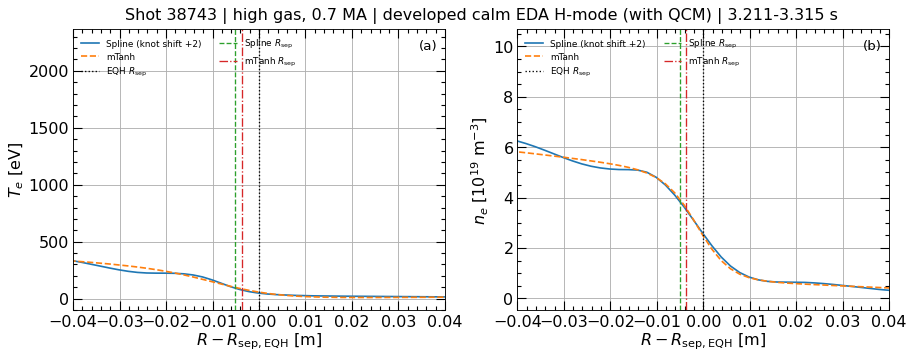

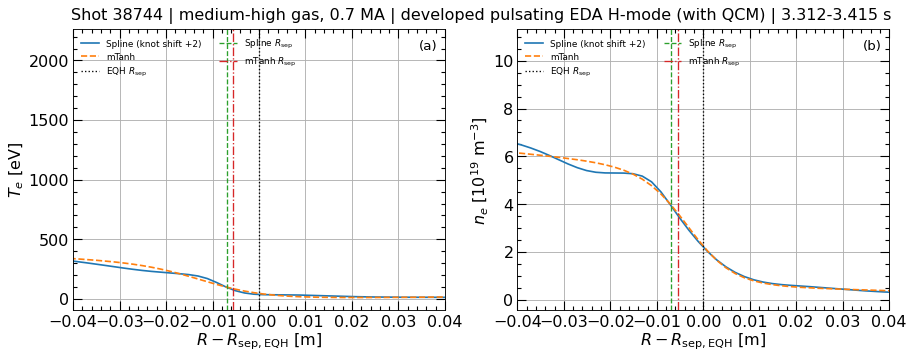

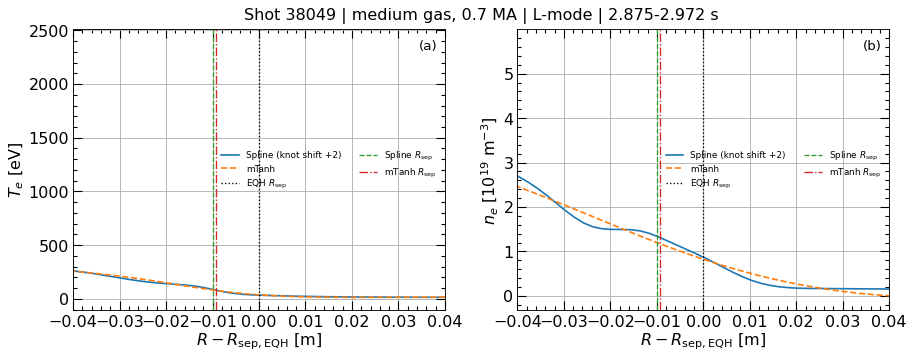

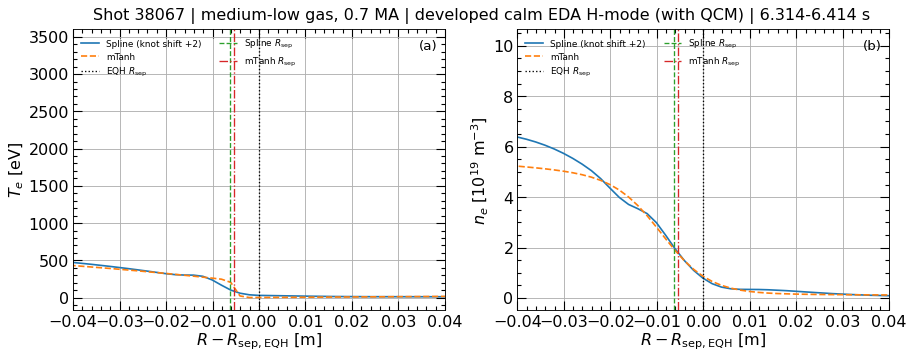

Rendered 4 matched-shot figures from saved fit JSON files.


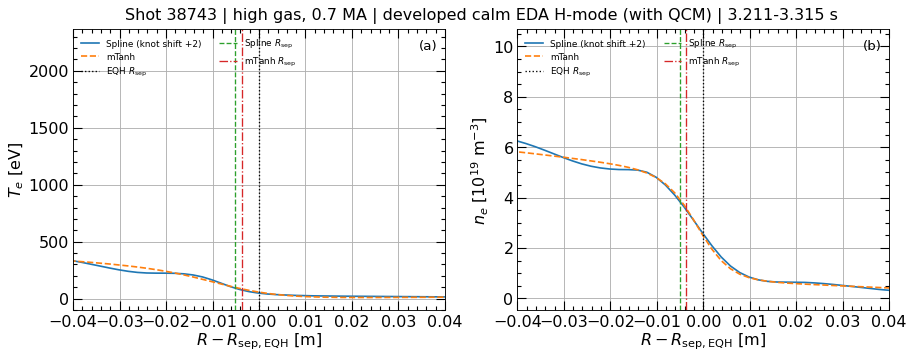

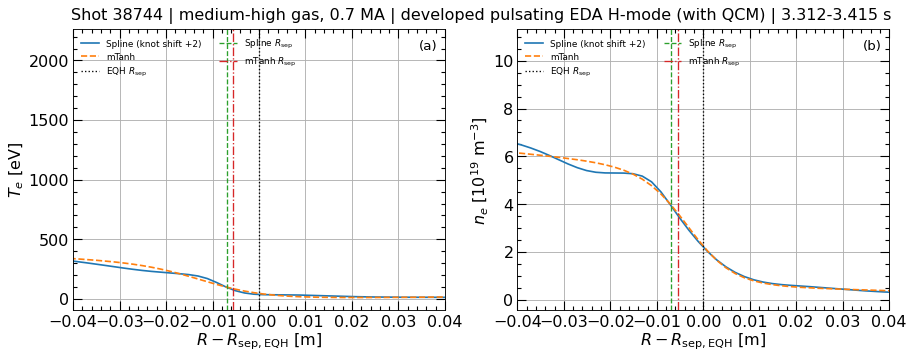

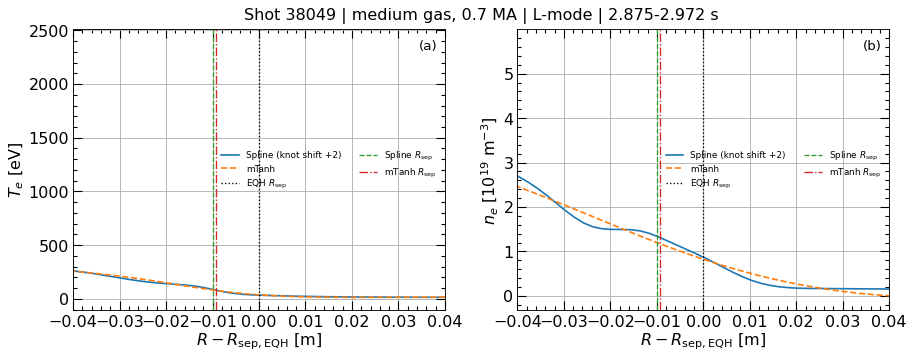

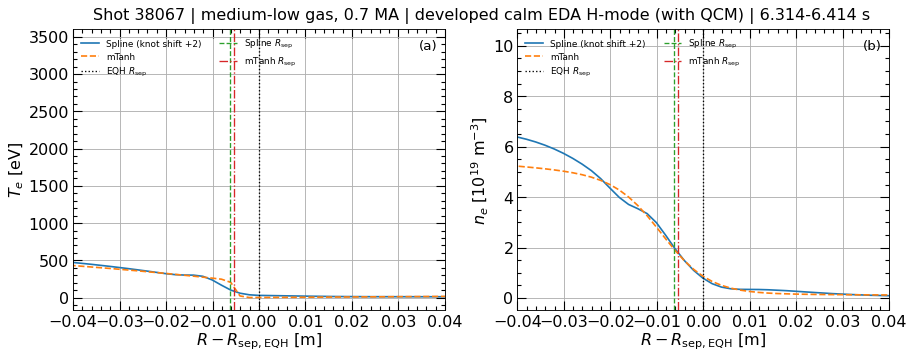

In [3]:
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import importlib

modified_tanh = importlib.import_module("ts_profile_fitter.fitting").modified_tanh


def evaluate_saved_profiles(result_path):
    result_path = Path(result_path)
    if not result_path.is_file():
        raise FileNotFoundError(f"Saved fit JSON not found: {result_path}")
    with result_path.open() as result_file:
        result = json.load(result_file)

    expected_metadata = {
        "equilibrium": CONFIG["equilibrium"],
        "diagnostic": CONFIG["diagnostic"],
        "fit_config_id": CONFIG["fit_config_id"],
        "spline_method": SPLINE_CONFIG["method"],
        "knot_strategy": SPLINE_CONFIG["knot_strategy"],
    }
    mismatches = {
        key: (result.get(key), expected)
        for key, expected in expected_metadata.items()
        if result.get(key) != expected
    }
    if mismatches:
        raise ValueError(f"Fit metadata does not match pinned config: {mismatches}")

    spline = result["spline"]
    degree = 3
    knots = np.asarray(spline["knots"], dtype=float)
    knot_vector = np.r_[
        np.repeat(knots[0], degree + 1),
        knots[1:-1],
        np.repeat(knots[-1], degree + 1),
    ]
    radius = np.asarray(spline["R_mid_spl"], dtype=float)
    te_spline = BSpline(
        knot_vector,
        np.asarray(spline["Te_params"], dtype=float),
        degree,
        extrapolate=False,
    )(radius)
    ne_spline = BSpline(
        knot_vector,
        np.asarray(spline["ne_params"], dtype=float),
        degree,
        extrapolate=False,
    )(radius)
    te_mtanh = modified_tanh(
        radius, *np.asarray(result["mtanh"]["Te"]["params"], dtype=float)
    )
    ne_mtanh = modified_tanh(
        radius, *np.asarray(result["mtanh"]["Ne"]["params"], dtype=float)
    )

    physics = result["physics"]
    rsep_eqh = float(physics["eqh"]["Rsep_eqh"])
    rsep_spline = float(physics["spline"]["Rsep"])
    rsep_mtanh = float(physics["mtanh"]["Rsep"])
    return {
        "result": result,
        "radius_relative": radius - rsep_eqh,
        "te_spline": np.asarray(te_spline, dtype=float),
        "te_mtanh": np.asarray(te_mtanh, dtype=float),
        "ne_spline": np.asarray(ne_spline, dtype=float),
        "ne_mtanh": np.asarray(ne_mtanh, dtype=float),
        "separatrix_offsets": {
            "EQH": 0.0,
            "Spline": rsep_spline - rsep_eqh,
            "mTanh": rsep_mtanh - rsep_eqh,
        },
    }


profile_comparisons = []
for row in selected_rows:
    result_path = Path(row["result"])
    profile = evaluate_saved_profiles(result_path)
    result_interval = profile["result"]["interval"]
    if not np.isclose(result_interval["t_begin"], row["t_begin (s)"], atol=0.002):
        raise ValueError(f"Start time in {result_path.name} does not match selected row")
    if not np.isclose(result_interval["t_end"], row["t_end (s)"], atol=0.002):
        raise ValueError(f"End time in {result_path.name} does not match selected row")
    profile.update(
        {
            "shot": int(row["shot"]),
            "case": GAS_SCAN_CASES[int(row["shot"])],
            "label": row["label"],
            "t_begin": float(row["t_begin (s)"]),
            "t_end": float(row["t_end (s)"]),
        }
    )
    profile_comparisons.append(profile)

FIGURES = []
for profile in profile_comparisons:
    radius_relative = profile["radius_relative"]
    fig, axes = ipfn_plots(
        x=[radius_relative] * 4,
        y=[
            profile["te_spline"],
            profile["te_mtanh"],
            profile["ne_spline"] / 1e19,
            profile["ne_mtanh"] / 1e19,
        ],
        labels=[SPLINE_LABEL, "mTanh", SPLINE_LABEL, "mTanh"],
        boxes=[0, 0, 1, 1],
        n_boxes=2,
        x_labels=r"$R - R_{\mathrm{sep,EQH}}$ [m]",
        y_labels=[r"$T_e$ [eV]", r"$n_e$ [$10^{19}$ m$^{-3}$]"],
        linestyles=["-", "--", "-", "--"],
        markers=[None] * 4,
        markersizes=[None] * 4,
        plot_kw=[
            {"color": "tab:blue"},
            {"color": "tab:orange"},
            {"color": "tab:blue"},
            {"color": "tab:orange"},
        ],
        title=f"Shot {profile['shot']} | {profile['case']} | "
        f"{profile['label']} | {profile['t_begin']:.3f}-{profile['t_end']:.3f} s",
        show=False,
        save_fig=False,
        close=False,
        ncols=2,
        figsize=(12, 4.5),
        sharex=True,
    )
    axes = np.asarray(axes, dtype=object).ravel()
    #axes[0].set_title("Electron temperature")
    #axes[1].set_title("Electron density")

    marker_style = {
        "EQH": ("black", ":"),
        "Spline": ("tab:green", "--"),
        "mTanh": ("tab:red", "-."),
    }
    for axis in axes:
        for model, offset in profile["separatrix_offsets"].items():
            color, linestyle = marker_style[model]
            axis.axvline(
                offset,
                color=color,
                linestyle=linestyle,
                linewidth=1.2,
                label=f"{model} $R_{{\mathrm{{sep}}}}$",
            )
        axis.set_xlim(*PEDESTAL_XLIM)
        axis.legend(frameon=False, fontsize=8, ncols=2)

    #fig.tight_layout(rect=(0, 0, 1, 0.90))
    FIGURES.append(fig)
    display(fig)

print(f"Rendered {len(FIGURES)} matched-shot figures from saved fit JSON files.")

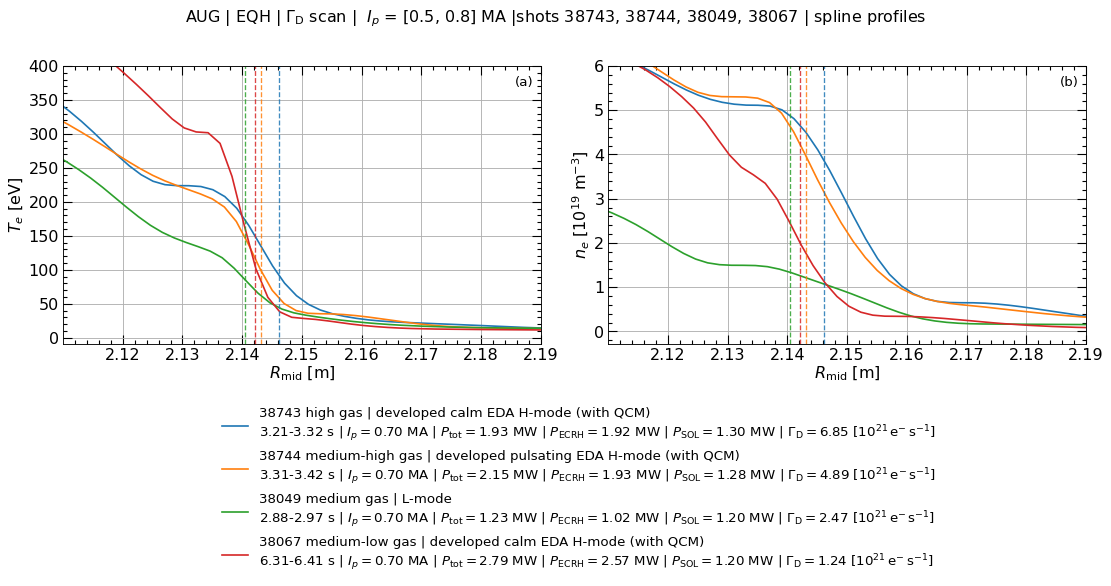

Gas-puff overlay uses spline profiles at matched P_SOL; each of the four legend labels includes the regime and interval.


In [11]:
# Choose "spline" or "mtanh" to select the overlaid profile and R_sep markers.
PROFILE_MODEL = "spline"
if PROFILE_MODEL not in {"spline", "mtanh"}:
    raise ValueError("PROFILE_MODEL must be either 'spline' or 'mtanh'")
if len(profile_comparisons) != len(selected_rows):
    raise ValueError("Profile results and selected interval rows do not line up")

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
if len(colors) != len(profile_comparisons):
    raise ValueError("The gas-scan palette must provide one color per selected shot")
case_specs = []
for color, profile, row in zip(colors, profile_comparisons, selected_rows):
    shot_id = int(row["shot"])
    radius_mid = np.asarray(profile["result"]["spline"]["R_mid_spl"], dtype=float)
    physics = profile["result"]["physics"]
    rsep = float(physics[PROFILE_MODEL]["Rsep"])
    gas_puff = float(pd.to_numeric(row[GAS_FIELD], errors="raise")) * GAS_PUFF_SCALE
    p_net_mw = float(row[P_NET_FIELD]) / 1e6
    p_sol_mw = float(row[SOL_FIELD]) / 1e6
    p_ecrh_mw = float(row[ECRH_FIELD]) / 1e6
    ip_ma = float(row[IP_FIELD]) / 1e6
    gas_case = GAS_SCAN_CASES[shot_id].split(",")[0]
    interval_start = float(row["t_begin (s)"])
    interval_end = float(row["t_end (s)"])
    regime = str(row["label"])
    case_specs.append(
        {
            "color": color,
            "radius_mid": radius_mid,
            "te": np.asarray(profile[f"te_{PROFILE_MODEL}"], dtype=float),
            "ne": np.asarray(profile[f"ne_{PROFILE_MODEL}"], dtype=float) / 1e19,
            "rsep": rsep,
            "label": (
                f"{shot_id} {gas_case} | {regime}\n"
                f"{interval_start:.2f}-{interval_end:.2f} s | "
                rf"$I_p={ip_ma:.2f}$ MA | "
                rf"$P_{{\mathrm{{tot}}}}={p_net_mw:.2f}$ MW | "
                rf"$P_{{\mathrm{{ECRH}}}}={p_ecrh_mw:.2f}$ MW | "
                rf"$P_{{\mathrm{{SOL}}}}={p_sol_mw:.2f}$ MW | "
                rf"$\Gamma_{{\mathrm{{D}}}}={gas_puff:.2f}$ [$10^{{21}}\,\mathrm{{e}}^{{-}}\,\mathrm{{s}}^{{-1}}$]"
            ),
        }
    )

n_cases = len(case_specs)
x_plot = [case["radius_mid"] for case in case_specs] * 2
y_plot = [case["te"] for case in case_specs] + [case["ne"] for case in case_specs]
plot_labels = [case["label"] for case in case_specs] * 2
plot_colors = [case["color"] for case in case_specs] * 2
plot_boxes = [0] * n_cases + [1] * n_cases
plot_kw = [{"color": color, "linewidth": 1.8} for color in plot_colors]
shot_labels = ", ".join(str(int(row["shot"])) for row in selected_rows)
fig, axes = ipfn_plots(
    x=x_plot,
    y=y_plot,
    labels=plot_labels,
    boxes=plot_boxes,
    n_boxes=2,
    x_labels=r"$R_{\mathrm{mid}}$ [m]",
    y_labels=[r"$T_e$ [eV]", r"$n_e$ [$10^{19}$ m$^{-3}$]"],
    linestyles=["-"] * (2 * n_cases),
    markers=[None] * (2 * n_cases),
    markersizes=[None] * (2 * n_cases),
    plot_kw=plot_kw,
    title=(
        #f"{CONFIG['equilibrium']} gas-puff scan | {MATCH_POWER_KIND} target "
        rf"AUG | {CONFIG['equilibrium']} | $\Gamma_{{\mathrm{{D}}}}$ scan | "
        f' $I_p$ = [0.5, 0.8] MA |'
        #f"{MATCH_POWER_KIND} target {MATCH_POWER_TARGET_MW:.2f} MW |"
        #f"{current_scan_model_label} profiles"
        f"shots {shot_labels} | {PROFILE_MODEL} profiles"
    ),
    show=False,
    save_fig=False,
    close=False,
    ncols=2,
    figsize=(14, 7),
    y_maxs_boxes=[400, 6],
    sharex=True,
)
axes = np.asarray(axes, dtype=object).ravel()
eqh_separatrices = [
    float(profile["result"]["physics"]["eqh"]["Rsep_eqh"])
    for profile in profile_comparisons
]
mean_eqh_separatrix = float(np.mean(eqh_separatrices))
absolute_radius_limits = (
    mean_eqh_separatrix + PEDESTAL_XLIM[0],
    mean_eqh_separatrix + PEDESTAL_XLIM[1],
)
for axis in axes:
    axis_legend = axis.get_legend()
    if axis_legend is not None:
        axis_legend.remove()
    for case in case_specs:
        axis.axvline(
            case["rsep"],
            color=case["color"],
            linestyle="--",
            linewidth=1.2,
            alpha=0.85,
        )
    axis.set_xlim(*absolute_radius_limits)

legend_handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(
    legend_handles,
    legend_labels,
    #title=(
    #    f"Matched {MATCH_POWER_KIND}: {MATCH_POWER_TARGET_MW:.2f} MW "
    #    f"+/- {MATCH_POWER_RELATIVE_TOLERANCE:.0%}; full interval details above"
    #),
    frameon=False,
    fontsize=12,
    title_fontsize=9,
    bbox_to_anchor=(0.85, 0.3),
    ncols=1,
)
fig.tight_layout(rect=(0, 0.30, 1, 0.92))
display(fig)
print(
    f"Gas-puff overlay uses {PROFILE_MODEL} profiles at matched {MATCH_POWER_KIND}; "
    "each of the four legend labels includes the regime and interval."
)

In [12]:
power_tag = f"{MATCH_POWER_KIND.lower()}_{MATCH_POWER_TARGET_MW:.2f}MW".replace(".", "p")
model_tag = PROFILE_MODEL.lower()
save_fig(fig=fig, name = f'actuator_pedestal_gas_puff_scan_{power_tag}_{model_tag}',
         directory=THESIS_FIGURES_DIR, format='pdf')

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Results/Fueling/figures/actuator_pedestal_gas_puff_scan_p_sol_1p30MW_spline.pdf


## Current Scan at Matched $P_{\\mathrm{SOL}}$ and Gas Puff

For shots 35970, 36124, 36980, and 38049, select successful fitted intervals near the same configured power target, each at least 0.08 s long with at least 100 fit data points. Do not filter by regime: preserve each interval's label in the summary and plot. Among those intervals, require the relative gas-puff span to be at most 6%, choose the best joint match, and sort the overlay by $I_p$. Report the selected interval, regime, fit points, gas puff, $P_{\\mathrm{tot}}$, $P_{\\mathrm{ECRH}}$, and $P_{\\mathrm{SOL}}$ for every shot.

Current-scan intervals after fit-quality and matched-power filters:


,shot,case,qualified intervals at target power,regimes represented
0,38808,"medium gas, 0.6 MA",9,1
1,36124,"medium gas, 0.8 MA",6,1
2,36980,"medium gas, 0.5 MA",4,2
3,38049,"medium gas, 0.7 MA",6,3


Feasible current-scan tuples: 1296; selected gas-puff span 5.64%, P_SOL span 1.43%, and Ip span 46.31%.


,shot,case,t_begin (s),t_end (s),duration (s),regime,fit points,fit status,matched power (MW),power offset from target (%),Ip (MA),Gamma_D (10^21 e-/s),P_tot (MW),P_ECRH (MW),P_SOL spline (MW),P_TOT-Pr_sep column (MW),fit JSON
0,36980,"medium gas, 0.5 MA",3.248333,3.341667,0.093333,alternating (developed): developed pulsating E...,151,ok,1.294417,-0.429445,0.496738,2.542835,1.413226,1.256525,1.294417,1.292559,interval_3.248_3.342.json
1,38808,"medium gas, 0.6 MA",5.648400,5.750700,0.102300,developed calm EDA H-mode (with QCM),187,ok,1.306729,0.517589,0.598456,2.571337,2.271262,2.191141,1.306729,1.306851,interval_5.648_5.751.json
2,38049,"medium gas, 0.7 MA",3.872222,3.974444,0.102222,alternating (developed): developed calm EDA H-...,193,ok,1.313111,1.008572,0.696903,2.473383,1.654612,1.372624,1.313111,1.324694,interval_3.872_3.974.json
3,36124,"medium gas, 0.8 MA",5.676667,5.783333,0.106667,developed pulsating EDA H-mode (with QCM),192,ok,1.297459,-0.195449,0.796401,2.617183,2.143367,1.823683,1.297459,1.300496,interval_5.677_5.783.json


,quantity,relative span (%),role
0,P_SOL (matched),1.434784,matched to target
1,Gas puff,5.636573,held within 6%
2,P_tot,45.869097,reported
3,P_ECRH,56.268498,reported
4,P_SOL spline,1.434784,reported
5,Ip,46.306985,scan variable


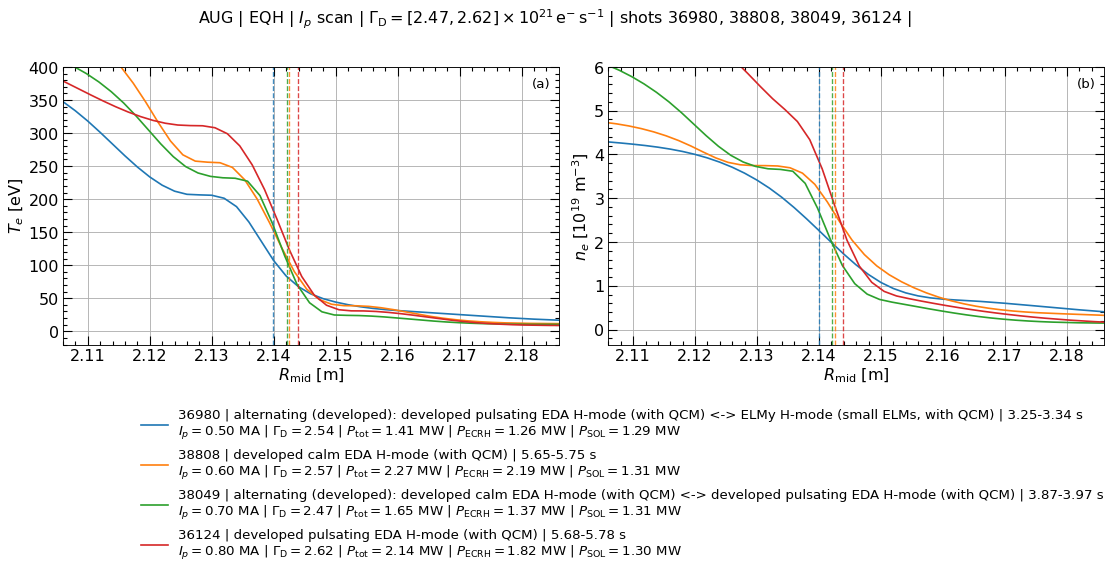

Rendered 4 current-scan profiles at spline; dashed lines mark each selected-model separatrix.


In [114]:
CURRENT_SCAN_MODEL = PROFILE_MODEL
if CURRENT_SCAN_MODEL not in {"spline", "mtanh"}:
    raise ValueError("PROFILE_MODEL must be either 'spline' or 'mtanh'")

current_scan_intervals, current_scan_candidates = load_power_matched_candidates(
    CURRENT_SCAN_SHOTS
)
current_scan_candidate_counts = pd.DataFrame(
    [
        {
            "shot": shot_id,
            "case": CURRENT_SCAN_CASES[shot_id],
            "qualified intervals at target power": int(
                (current_scan_candidates["shot"] == shot_id).sum()
            ),
            "regimes represented": int(
                current_scan_candidates.loc[
                    current_scan_candidates["shot"] == shot_id, "label"
                ].nunique()
            ),
        }
        for shot_id in CURRENT_SCAN_SHOTS
    ]
)
print("Current-scan intervals after fit-quality and matched-power filters:")
display(current_scan_candidate_counts)

current_scan_groups = {
    shot_id: current_scan_candidates.loc[
        current_scan_candidates["shot"] == shot_id
    ]
    .sort_values(["t_begin (s)", "t_end (s)"])
    .to_dict("records")
    for shot_id in CURRENT_SCAN_SHOTS
}
current_scan_empty = [shot_id for shot_id, rows in current_scan_groups.items() if not rows]
if current_scan_empty:
    raise ValueError(
        f"No qualified matched-power intervals for current-scan shot(s): {current_scan_empty}"
    )

CURRENT_SCAN_GAS_SPAN_LIMIT = MAX_RELATIVE_SPAN["Gas puff"]
current_scan_feasible = []
for combination in itertools.product(*(current_scan_groups[shot] for shot in CURRENT_SCAN_SHOTS)):
    power_values = np.array([row["matched power (MW)"] for row in combination], dtype=float)
    gas_values = np.array([row[GAS_FIELD] for row in combination], dtype=float)
    if not np.isfinite(np.r_[power_values, gas_values]).all() or abs(gas_values.mean()) == 0:
        continue
    gas_span = float(np.ptp(gas_values) / abs(gas_values.mean()))
    if gas_span > CURRENT_SCAN_GAS_SPAN_LIMIT:
        continue
    power_offsets = (power_values - MATCH_POWER_TARGET_MW) / (
        MATCH_POWER_TARGET_MW * MATCH_POWER_RELATIVE_TOLERANCE
    )
    score = float(
        np.sum(power_offsets**2) + (gas_span / CURRENT_SCAN_GAS_SPAN_LIMIT) ** 2
    )
    current_scan_feasible.append(
        {
            "score": score,
            "gas_span": gas_span,
            "power_span": float(np.ptp(power_values) / abs(power_values.mean())),
            "rows": combination,
        }
    )

if not current_scan_feasible:
    raise ValueError(
        f"No four-shot tuple matches {MATCH_POWER_KIND} near "
        f"{MATCH_POWER_TARGET_MW:.2f} MW and keeps gas-puff span within "
        f"{CURRENT_SCAN_GAS_SPAN_LIMIT:.1%}; no limits were widened."
    )
CURRENT_SCAN_MATCH = min(current_scan_feasible, key=lambda match: match["score"])
current_scan_rows = sorted(
    CURRENT_SCAN_MATCH["rows"],
    key=lambda row: float(row[IP_FIELD]),
)
current_scan_ip_values = np.array([row[IP_FIELD] for row in current_scan_rows], dtype=float)
print(
    f"Feasible current-scan tuples: {len(current_scan_feasible)}; selected gas-puff span "
    f"{CURRENT_SCAN_MATCH['gas_span']:.2%}, {MATCH_POWER_KIND} span "
    f"{CURRENT_SCAN_MATCH['power_span']:.2%}, and Ip span "
    f"{np.ptp(current_scan_ip_values) / abs(current_scan_ip_values.mean()):.2%}."
)

current_scan_intervals_table = pd.DataFrame(
    [
        {
            "shot": int(row["shot"]),
            "case": CURRENT_SCAN_CASES[int(row["shot"])],
            "t_begin (s)": row["t_begin (s)"],
            "t_end (s)": row["t_end (s)"],
            "duration (s)": row["duration_s"],
            "regime": row["label"],
            "fit points": int(row["fit points"]),
            "fit status": row["status"],
            "matched power (MW)": row["matched power (MW)"],
            "power offset from target (%)": 100
            * (row["matched power (MW)"] / MATCH_POWER_TARGET_MW - 1),
            "Ip (MA)": row[IP_FIELD] / 1e6,
            "Gamma_D (10^21 e-/s)": row[GAS_FIELD] * GAS_PUFF_SCALE,
            "P_tot (MW)": row[P_NET_FIELD] / 1e6,
            "P_ECRH (MW)": row[ECRH_FIELD] / 1e6,
            "P_SOL spline (MW)": row[SOL_FIELD] / 1e6,
            "P_TOT-Pr_sep column (MW)": pd.to_numeric(
                row.get(SOL_DATABASE_FIELD), errors="coerce"
            )
            / 1e6,
            "fit JSON": Path(row["result"]).name,
        }
        for row in current_scan_rows
    ]
)
display(current_scan_intervals_table)

current_scan_metric_fields = [
    (f"{MATCH_POWER_KIND} (matched)", "matched power (MW)", 1.0, "matched to target"),
    ("Gas puff", GAS_FIELD, GAS_PUFF_SCALE, f"held within {CURRENT_SCAN_GAS_SPAN_LIMIT:.0%}"),
    ("P_tot", P_NET_FIELD, 1e-6, "reported"),
    ("P_ECRH", ECRH_FIELD, 1e-6, "reported"),
    ("P_SOL spline", SOL_FIELD, 1e-6, "reported"),
    ("Ip", IP_FIELD, 1e-6, "scan variable"),
]
current_scan_spans = []
for name, field, scale, role in current_scan_metric_fields:
    values = np.array([float(row[field]) * scale for row in current_scan_rows])
    current_scan_spans.append(
        {
            "quantity": name,
            "relative span (%)": 100 * np.ptp(values) / abs(values.mean()),
            "role": role,
        }
    )
display(pd.DataFrame(current_scan_spans))

current_scan_profiles = []
for row in current_scan_rows:
    result_path = Path(row["result"])
    profile = evaluate_saved_profiles(result_path)
    result_interval = profile["result"]["interval"]
    if not np.isclose(result_interval["t_begin"], row["t_begin (s)"], atol=0.002):
        raise ValueError(f"Start time in {result_path.name} does not match selected row")
    if not np.isclose(result_interval["t_end"], row["t_end (s)"], atol=0.002):
        raise ValueError(f"End time in {result_path.name} does not match selected row")
    current_scan_profiles.append(profile)

current_scan_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
current_scan_cases = []
for color, profile, row in zip(current_scan_colors, current_scan_profiles, current_scan_rows):
    physics = profile["result"]["physics"]
    current = float(row[IP_FIELD]) / 1e6
    gas_puff = float(row[GAS_FIELD]) * GAS_PUFF_SCALE
    p_net = float(row[P_NET_FIELD]) / 1e6
    p_ecrh = float(row[ECRH_FIELD]) / 1e6
    p_sol = float(row[SOL_FIELD]) / 1e6
    interval_start = float(row["t_begin (s)"])
    interval_end = float(row["t_end (s)"])
    current_scan_cases.append(
        {
            "color": color,
            "shot": int(row["shot"]),
            "radius_mid": np.asarray(profile["result"]["spline"]["R_mid_spl"], dtype=float),
            "te": np.asarray(profile[f"te_{CURRENT_SCAN_MODEL}"], dtype=float),
            "ne": np.asarray(profile[f"ne_{CURRENT_SCAN_MODEL}"], dtype=float) / 1e19,
            "rsep": float(physics[CURRENT_SCAN_MODEL]["Rsep"]),
            "label": (
                f"{int(row['shot'])} | {row['label']} | "
                f"{interval_start:.2f}-{interval_end:.2f} s\n"
                rf"$I_p={current:.2f}$ MA | "
                rf"$\Gamma_{{\mathrm{{D}}}}={gas_puff:.2f}$ | "
                rf"$P_{{\mathrm{{tot}}}}={p_net:.2f}$ MW | "
                rf"$P_{{\mathrm{{ECRH}}}}={p_ecrh:.2f}$ MW | "
                rf"$P_{{\mathrm{{SOL}}}}={p_sol:.2f}$ MW"
            ),
        }
    )

n_current_scan_cases = len(current_scan_cases)
current_scan_x = [case["radius_mid"] for case in current_scan_cases] * 2
current_scan_y = [case["te"] for case in current_scan_cases] + [
    case["ne"] for case in current_scan_cases
]
current_scan_plot_labels = [case["label"] for case in current_scan_cases] * 2
current_scan_plot_colors = [case["color"] for case in current_scan_cases] * 2
current_scan_plot_boxes = [0] * n_current_scan_cases + [1] * n_current_scan_cases
current_scan_plot_kw = [
    {"color": color, "linewidth": 1.8} for color in current_scan_plot_colors
]
current_scan_shot_text = ", ".join(str(case["shot"]) for case in current_scan_cases)
current_scan_model_label = SPLINE_LABEL if CURRENT_SCAN_MODEL == "spline" else "mTanh"
current_scan_gas_values = np.array(
    [float(row[GAS_FIELD]) * GAS_PUFF_SCALE for row in current_scan_rows], dtype=float
)
current_scan_gas_min = float(current_scan_gas_values.min())
current_scan_gas_max = float(current_scan_gas_values.max())
current_scan_fig, current_scan_axes = ipfn_plots(
    x=current_scan_x,
    y=current_scan_y,
    labels=current_scan_plot_labels,
    boxes=current_scan_plot_boxes,
    n_boxes=2,
    x_labels=r"$R_{\mathrm{mid}}$ [m]",
    y_labels=[r"$T_e$ [eV]", r"$n_e$ [$10^{19}$ m$^{-3}$]"],
    linestyles=["-"] * (2 * n_current_scan_cases),
    markers=[None] * (2 * n_current_scan_cases),
    markersizes=[None] * (2 * n_current_scan_cases),
    title=(
        f"AUG | {CONFIG['equilibrium']} | $I_p$ scan | "
        rf"$\Gamma_{{\mathrm{{D}}}}=[{current_scan_gas_min:.2f}, {current_scan_gas_max:.2f}]\times10^{{21}}\,\mathrm{{e}}^{{-}}\,\mathrm{{s}}^{{-1}}$ | "
        #f"{MATCH_POWER_KIND} target {MATCH_POWER_TARGET_MW:.2f} MW |"
        f"shots {current_scan_shot_text} | "
        #f"{current_scan_model_label} profiles"
    ),
    plot_kw=current_scan_plot_kw,
    show=False,
    save_fig=False,
    close=False,
    ncols=2,
    figsize=(14, 7),
    y_maxs_boxes=[400, 6],
    sharex=True,
)
current_scan_axes = np.asarray(current_scan_axes, dtype=object).ravel()
current_scan_eqh = [
    float(profile["result"]["physics"]["eqh"]["Rsep_eqh"])
    for profile in current_scan_profiles
]
current_scan_mean_eqh = float(np.mean(current_scan_eqh))
current_scan_xlim = (
    current_scan_mean_eqh + PEDESTAL_XLIM[0],
    current_scan_mean_eqh + PEDESTAL_XLIM[1],
)
for axis in current_scan_axes:
    axis_legend = axis.get_legend()
    if axis_legend is not None:
        axis_legend.remove()
    for case in current_scan_cases:
        axis.axvline(
            case["rsep"],
            color=case["color"],
            linestyle="--",
            linewidth=1.2,
            alpha=0.85,
        )
    axis.set_xlim(*current_scan_xlim)

current_scan_legend_handles, current_scan_legend_labels = (
    current_scan_axes[0].get_legend_handles_labels()
)
current_scan_fig.legend(
    current_scan_legend_handles,
    current_scan_legend_labels,
    #title=(
    #    f"Matched {MATCH_POWER_KIND}: {MATCH_POWER_TARGET_MW:.2f} MW "
    #    f"+/- {MATCH_POWER_RELATIVE_TOLERANCE:.0%}; gas-puff span "
    #    f"{CURRENT_SCAN_MATCH['gas_span']:.2%}; labels include regime and interval"
    #),
    frameon=False,
    fontsize=12,
    title_fontsize=9,
    #loc="lower center",
    bbox_to_anchor=(1, 0.3),
    ncols=1,
)
current_scan_fig.tight_layout(rect=(0, 0.30, 1, 0.92))
display(current_scan_fig)
print(
    f"Rendered {len(current_scan_cases)} current-scan profiles at {CURRENT_SCAN_MODEL}; "
    "dashed lines mark each selected-model separatrix."
)

In [115]:
THESIS_FIGURES_DIR = Path(
    "/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/"
    "chapters/Results/Plasma_Current/figures"
)

In [116]:
power_tag = f"{MATCH_POWER_KIND.lower()}_{MATCH_POWER_TARGET_MW:.2f}MW".replace(".", "p")
model_tag = PROFILE_MODEL.lower()
save_fig(fig=current_scan_fig, name = f'actuator_pedestal_current_scan_{power_tag}_{model_tag}',
         directory=THESIS_FIGURES_DIR, format='pdf')

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Results/Plasma_Current/figures/actuator_pedestal_current_scan_p_sol_1p30MW_spline.pdf


In [103]:
current_scan_rows[1]

{'shot': 38808,
 't_begin (s)': 5.9553,
 't_end (s)': 6.0576,
 'label': 'developed calm EDA H-mode (with QCM)',
 'BPD|Pradtot': 1542292.5,
 'BPT|Pr_div': 257558.953125,
 'BPT|Pr_main': 1486803.125,
 'BPT|Pr_sep': 986846.125,
 'BPT|Pr_sepX': 940199.125,
 'BPT|Pr_tot': 1744362.125,
 'DDS|nDivIst': 2.541196331869379e+19,
 'DDS|nMainIst': 1.8574397648572247e+18,
 'ECS|PECRH': 2298809.5,
 'FPC|IpiFP': 598273.125,
 'GIW|c_W': nan,
 'GIW|c_W_l': nan,
 'GQH|XPfdif': 0.0501693077385425,
 'GQH|betpol': 1.1534624099731443,
 'GQH|bver': 0.7565909028053284,
 'GQH|dRXP': -0.0153548894450068,
 'GQH|delRoben': 0.3022993803024292,
 'GQH|delRuntn': 0.494594544172287,
 'GQH|fax-bnd': 0.9527490139007568,
 'GQH|fbnd-ref': 0.1576888114213943,
 'GQH|q0': -1.7991673946380615,
 'GQH|q95': -6.583878517150879,
 'ICP|PICRN': nan,
 'IDA|Te': 1211.7685546875,
 'IDA|ne': 5.377575471815223e+19,
 'IDA|pe': 15286.224609375,
 'IDZ|Zeff': 1.3077785968780518,
 'IOC|F03': 6.511548661532048e+21,
 'IOC|F04': 4.4735054487605e